# Projet Leyenda - Livrable 2
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [54]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input


## Etape 1 : Chargement des données



In [55]:
DATA_DIR = Path("data")

ANNOTATION_FILES = {
    "train": DATA_DIR / "annotations" / "captions_train2014.json",
    "validation": DATA_DIR / "annotations" / "captions_val2014.json",
}

IMAGE_DIRS = {
    "train": DATA_DIR / "train2014",
    "validation": DATA_DIR / "val2014",
}


def load_split(split):
    try:
        with ANNOTATION_FILES[split].open("r", encoding="utf-8") as f:
            data = json.load(f)
    except UnicodeDecodeError:
        with ANNOTATION_FILES[split].open("r", encoding="cp1252") as f:
            data = json.load(f)
    
    records = {}
    for image in data["images"]:
        image_id = image["id"]
        if image_id in records:
            raise ValueError(f"{split} : ID image dupliqué {image_id}")
        records[image_id] = {
            "image_id": image_id,
            "image_path": IMAGE_DIRS[split] / image["file_name"],
            "captions": [],
        }

    
    for ann in data["annotations"]:
        image_id = ann["image_id"]
        if image_id not in records:
            raise ValueError(f"{split} : légende liée à une image inconnue {image_id}")
        records[image_id]["captions"].append(ann["caption"])

    
    missing_files = [r["image_path"] for r in records.values() if not r["image_path"].is_file()]
    no_caption = [i for i, r in records.items() if not r["captions"]]
    n_captions = sum(len(r["captions"]) for r in records.values())

    print(f"{split} : {len(records):,} images, {n_captions:,} légendes")
    print(f"  images introuvables sur disque : {len(missing_files)}")
    print(f"  images sans légende            : {len(no_caption)}")

    if missing_files:
        print("  exemples manquants :", missing_files[:3])

    return records


train_records = load_split("train")
val_records = load_split("validation")

shared = set(train_records) & set(val_records)
print("IDs communs train/validation :", len(shared))

train : 82,783 images, 414,113 légendes
  images introuvables sur disque : 0
  images sans légende            : 0
validation : 40,504 images, 202,654 légendes
  images introuvables sur disque : 0
  images sans légende            : 0
IDs communs train/validation : 0


In [56]:
example = next(iter(train_records.values()))

print("ID image :", example["image_id"])
print("Chemin :", example["image_path"])

for caption in example["captions"]:
    print("-", caption)

ID image : 57870
Chemin : data\train2014\COCO_train2014_000000057870.jpg
- A restaurant has modern wooden tables and chairs.
- A long restaurant table with rattan rounded back chairs.
- a long table with a plant on top of it surrounded with wooden chairs 
- A long table with a flower arrangement in the middle for meetings
- A table is adorned with wooden chairs with blue accents.


# Etape 2 : Prétraitement des données

In [57]:
IMAGE_SIZE = (299, 299)
BATCH_SIZE = 32

inception = InceptionV3(
    weights="imagenet",
    include_top=False,
    pooling=None,
    input_shape=(*IMAGE_SIZE, 3),
)

inception.trainable = False

inputs = Input(
    shape=(*IMAGE_SIZE, 3),
    name="image_input",
)


outputs = inception(inputs, training=False)

image_encoder = Model(
    inputs=inputs,
    outputs=outputs,
    name="image_encoder",
)

print("Entrée :", image_encoder.input_shape)
print("Sortie :", image_encoder.output_shape)

Entrée : (None, 299, 299, 3)
Sortie : (None, 8, 8, 2048)


Charger et preprocess 

In [58]:
def load_and_preprocess_image(image_id, image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image_bytes,
        channels=3,
    )

    image = tf.image.resize(image, IMAGE_SIZE)
    image = preprocess_input(image)

    return image_id, image

Créer le dataset avec le lien image id et image path

In [59]:
def make_image_dataset(records):
    image_ids = np.array(list(records.keys()), dtype=np.int64)

    image_paths = [
        str(records[int(image_id)]["image_path"])
        for image_id in image_ids
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_ids, image_paths)
    )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_image_dataset = make_image_dataset(train_records)
val_image_dataset = make_image_dataset(val_records)

print("Datasets train et validation créés.")

Datasets train et validation créés.


Test avec un batch

In [60]:

batch_ids, batch_images = next(iter(train_image_dataset))

batch_features = image_encoder(batch_images, training=False)

batch_features = tf.reshape(
    batch_features,
    (tf.shape(batch_features)[0], 64, 2048),
)

print("Caractéristiques :", batch_features.shape)


Caractéristiques : (32, 64, 2048)


## Extraction des features

In [61]:
FEATURES_DIR = Path("features/inception_grid_fp16")

N_TRAIN_IMAGES = 30_000
N_VAL_IMAGES = 10_000
SEED = 42


def extract_features(records, split_name, n_images=None):
    out_dir = FEATURES_DIR / split_name
    out_dir.mkdir(parents=True, exist_ok=True)

   
    if n_images is not None:
        all_ids = np.array(sorted(records), dtype=np.int64)
        rng = np.random.default_rng(SEED)
        selected = rng.choice(all_ids, size=min(n_images, len(all_ids)), replace=False)
        records = {int(i): records[int(i)] for i in selected}

    pending = [i for i in records if not (out_dir / f"{i}.npy").exists()]
    already_done = len(records) - len(pending)

    print(f"{split_name} : {len(records):,} images retenues, "
          f"{already_done:,} déjà faites, {len(pending):,} à traiter")
    if not pending:
        return

    dataset = make_image_dataset({i: records[i] for i in pending})
    total_batches = (len(pending) + BATCH_SIZE - 1) // BATCH_SIZE

    start = time.time()
    done = 0

    for batch_number, (image_ids, images) in enumerate(dataset, start=1):
        features = image_encoder(images, training=False)                      
        features = tf.reshape(features, (tf.shape(features)[0], 64, 2048))   
        features = features.numpy().astype(np.float16)

        for image_id, vector in zip(image_ids.numpy(), features):
            tmp_path = out_dir / f"{image_id}.tmp.npy"
            np.save(tmp_path, vector)
            tmp_path.replace(out_dir / f"{image_id}.npy")

        done += len(features)

        if batch_number % 100 == 0 or batch_number == total_batches:
            speed = done / (time.time() - start)
            print(f"{split_name} : {batch_number}/{total_batches} batches, {speed:.1f} images/s", flush=True)

In [62]:
extract_features(train_records, "train", n_images=N_TRAIN_IMAGES)
extract_features(val_records, "validation", n_images=N_VAL_IMAGES)

train : 30,000 images retenues, 30,000 déjà faites, 0 à traiter
validation : 10,000 images retenues, 10,000 déjà faites, 0 à traiter


In [63]:
for split, records in [("train", train_records), ("validation", val_records)]:
    out_dir = FEATURES_DIR / split
    files = [p for p in out_dir.glob("*.npy") if not p.name.endswith(".tmp.npy")]
    print(f"{split} : {len(files):,} fichiers pour {len(records):,} images")

example = np.load(files[0])
print("Forme :", example.shape, "| type :", example.dtype)   # attendu : (64, 2048) float16

train : 30,000 fichiers pour 82,783 images
validation : 10,000 fichiers pour 40,504 images
Forme : (64, 2048) | type : float16


Prépare caption

In [64]:
def prepare_captions(records):
    image_ids = []
    captions = []

    for image_id, record in records.items():
        for caption in record["captions"]:
            image_ids.append(image_id)
            captions.append(f"startseq {caption.strip()} endseq")

    return np.asarray(image_ids, dtype=np.int64), captions


train_caption_image_ids, train_captions = prepare_captions(train_records)
val_caption_image_ids, val_captions = prepare_captions(val_records)

print("Légendes train :", len(train_captions))
print("Légendes validation :", len(val_captions))

Légendes train : 414113
Légendes validation : 202654


Tokenizer

In [65]:
TOP_K = 5000

tokenizer = Tokenizer(num_words=TOP_K, oov_token="unk")
tokenizer.fit_on_texts(train_captions)   

train_sequences = tokenizer.texts_to_sequences(train_captions)
val_sequences = tokenizer.texts_to_sequences(val_captions)

vocab_size = min(TOP_K, len(tokenizer.word_index))

start_token_id = tokenizer.word_index["startseq"]
end_token_id = tokenizer.word_index["endseq"]

assert start_token_id < vocab_size
assert end_token_id < vocab_size

print("vocab_size :", vocab_size)
print("startseq :", start_token_id, "| endseq :", end_token_id)

vocab_size : 5000
startseq : 3 | endseq : 4


In [66]:
max_length = 20 # Ancien max(len(sequence) for sequence in train_sequences)

val_sequences = [
    sequence
    if len(sequence) <= max_length
    else sequence[:max_length - 1] + [end_token_id]
    for sequence in val_sequences
]

train_caption_tokens = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post",
    value=0,
    dtype="int32",
)

val_caption_tokens = pad_sequences(
    val_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post",
    value=0,
    dtype="int32",
)

print("Longueur maximale :", max_length)
print("Train :", train_caption_tokens.shape)
print("Validation :", val_caption_tokens.shape)

Longueur maximale : 20
Train : (414113, 20)
Validation : (202654, 20)


In [67]:
print("vocab_size :", vocab_size)
print("max_length :", max_length)
print("indice max dans train :", train_caption_tokens.max())
print("indice max dans validation :", val_caption_tokens.max())
print("unk :", tokenizer.word_index["unk"],
      "| startseq :", start_token_id,
      "| endseq :", end_token_id)

assert train_caption_tokens.max() < vocab_size
assert val_caption_tokens.max() < vocab_size

vocab_size : 5000
max_length : 20
indice max dans train : 4999
indice max dans validation : 4999
unk : 1 | startseq : 3 | endseq : 4


Encodeur CNN

In [68]:
EMBEDDING_DIM = 256

class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = tf.keras.layers.Dense(
            embedding_dim,
            kernel_regularizer=tf.keras.regularizers.l2(1e-5),  # ← AJOUT
        )

    def call(self, x):
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x


encoder = CNN_Encoder(EMBEDDING_DIM)

## Mécanisme d’attention de Bahdanau

In [69]:
class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units):
        super().__init__()

        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        

        hidden_with_time_axis = tf.expand_dims(hidden, axis=1)

        
        attention_hidden = tf.nn.tanh(
            self.W1(features) + self.W2(hidden_with_time_axis)
        )

        
        scores = self.V(attention_hidden)

        
        attention_weights = tf.nn.softmax(scores, axis=1)

        
        context_vector = tf.reduce_sum(
            attention_weights * features,
            axis=1,
        )

        return context_vector, attention_weights

In [70]:
RNN_UNITS = 512
ATTENTION_UNITS = 512


attention_test = BahdanauAttention(ATTENTION_UNITS)

encoded_features = encoder(batch_features)


hidden_test = tf.zeros(
    (tf.shape(encoded_features)[0], RNN_UNITS),
    dtype=encoded_features.dtype,
)

context_vector, attention_weights = attention_test(
    encoded_features,
    hidden_test,
)

print("Caractéristiques encodées :", encoded_features.shape)
print("État caché :", hidden_test.shape)
print("Vecteur de contexte :", context_vector.shape)
print("Poids d’attention :", attention_weights.shape)

tf.debugging.assert_near(
    tf.reduce_sum(attention_weights, axis=1),
    tf.ones_like(attention_weights[:, 0, :]),
    atol=1e-5,
)

tf.debugging.assert_all_finite(
    context_vector,
    "Le vecteur de contexte contient des valeurs invalides.",
)

Caractéristiques encodées : (32, 64, 256)
État caché : (32, 512)
Vecteur de contexte : (32, 256)
Poids d’attention : (32, 64, 1)


<tf.Tensor: shape=(32, 256), dtype=float32, numpy=
array([[0.28853247, 0.279088  , 0.01666328, ..., 0.24714518, 0.00592253,
        0.06907427],
       [0.5900242 , 0.2920416 , 0.00353856, ..., 0.23383088, 0.01205993,
        0.09423124],
       [0.19137904, 0.6926157 , 0.05984322, ..., 0.40769863, 0.00272834,
        0.01776082],
       ...,
       [0.2876271 , 0.04080332, 0.01501855, ..., 0.15716204, 0.        ,
        0.05564334],
       [0.12419377, 0.20090088, 0.01700885, ..., 0.2154469 , 0.00401068,
        0.17210288],
       [0.21252756, 0.28850788, 0.02379495, ..., 1.1017672 , 0.1207747 ,
        0.02057896]], shape=(32, 256), dtype=float32)>

## Décodeur RNN

In [71]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super().__init__()
        self.units = units
        self.embedding = layers.Embedding(vocab_size, embedding_dim)
        self.attention = BahdanauAttention(units)
        self.lstm = layers.LSTM(units, return_sequences=True, return_state=True,
                                dropout=0.3)   # ← AJOUT
        self.fc1 = layers.Dense(units,
                                kernel_regularizer=tf.keras.regularizers.l2(1e-5))  # ← AJOUT
        self.fc2 = layers.Dense(vocab_size,
                                kernel_regularizer=tf.keras.regularizers.l2(1e-5))  # ← AJOUT
        self.dropout = layers.Dropout(0.3)     # ← AJOUT

    def call(self, word_id, features, hidden, cell, training=False):   # ← training ajouté
        context_vector, attention_weights = self.attention(features, hidden)

        x = self.embedding(word_id)
        x = self.dropout(x, training=training)                # ← AJOUT

        context = tf.expand_dims(context_vector, axis=1)
        x = tf.concat([context, x], axis=-1)

        output, hidden, cell = self.lstm(x, initial_state=[hidden, cell],
                                         training=training)   # ← training passé au LSTM

        x = self.fc1(output)
        x = tf.reshape(x, (-1, x.shape[2]))
        x = self.dropout(x, training=training)                # ← AJOUT
        logits = self.fc2(x)

        return logits, hidden, cell, attention_weights

    def reset_state(self, batch_size):
        zeros = tf.zeros((batch_size, self.units))
        return zeros, zeros


decoder = RNN_Decoder(EMBEDDING_DIM, RNN_UNITS, vocab_size)

test


In [72]:
batch_size = encoded_features.shape[0]
hidden, cell = decoder.reset_state(batch_size)
word_id = tf.fill((batch_size, 1), start_token_id)

logits, hidden, cell, attn = decoder(word_id, encoded_features, hidden, cell)

print("Mot en entrée :", word_id.shape)
print("Scores        :", logits.shape)
print("État caché h  :", hidden.shape)
print("État cellule c:", cell.shape)
print("Attention     :", attn.shape)

Mot en entrée : (32, 1)
Scores        : (32, 5000)
État caché h  : (32, 512)
État cellule c: (32, 512)
Attention     : (32, 64, 1)


Dataset final

In [84]:
N_TRAIN_IMAGES = 30_000
N_VAL_IMAGES = 10_000
SEED = 42
SHUFFLE_BUFFER = 1000


def load_feature_file(path):
    if isinstance(path, bytes):
        path = path.decode("utf-8")
    else:
        path = str(path)
    features = np.load(path, allow_pickle=False)
    return features.astype(np.float32)


def load_features_and_caption(feature_path, caption):
    features = tf.numpy_function(
        load_feature_file,
        [feature_path],
        Tout=tf.float32,
    )

    features = tf.ensure_shape(features, (64, 2048))
    caption = tf.ensure_shape(caption, (max_length,))

    return features, caption


def make_caption_dataset(
    image_ids,
    caption_tokens,
    split_name,
    training=False,
    n_images=None,
):
    image_ids = np.asarray(image_ids, dtype=np.int64)
    caption_tokens = np.asarray(caption_tokens, dtype=np.int32)

    if len(image_ids) != len(caption_tokens):
        raise ValueError("Les IDs et les légendes ne sont pas alignés.")

    unique_ids = np.unique(image_ids)

    if n_images is not None:
        rng = np.random.default_rng(SEED)
        selected_ids = rng.choice(
            unique_ids,
            size=min(n_images, len(unique_ids)),
            replace=False,
        )

        mask = np.isin(image_ids, selected_ids)
        image_ids = image_ids[mask]
        caption_tokens = caption_tokens[mask]
        unique_ids = np.unique(image_ids)

    if len(image_ids) == 0:
        raise ValueError(f"{split_name} : aucune légende sélectionnée.")

    feature_dir = FEATURES_DIR / split_name

    missing_ids = [
        int(image_id)
        for image_id in unique_ids
        if not (feature_dir / f"{image_id}.npy").is_file()
    ]

    if missing_ids:
        raise FileNotFoundError(
            f"{split_name} : features manquantes pour "
            f"{len(missing_ids)} images. "
            f"Premiers IDs : {missing_ids[:5]}. "
            "Lance l'extraction pour les images sélectionnées."
        )

    feature_paths = [
        str(feature_dir / f"{image_id}.npy")
        for image_id in image_ids
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (feature_paths, caption_tokens)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_ids),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_features_and_caption,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    print(
        f"{split_name} : {len(unique_ids):,} images, "
        f"{len(caption_tokens):,} légendes"
    )
    print(f"Exemple : ID {image_ids[0]} → {feature_paths[0]}")

    return dataset, unique_ids


train_dataset, train_selected_ids = make_caption_dataset(
    train_caption_image_ids,
    train_caption_tokens,
    split_name="train",
    training=True,
    n_images=N_TRAIN_IMAGES,
)

val_dataset, val_selected_ids = make_caption_dataset(
    val_caption_image_ids,
    val_caption_tokens,
    split_name="validation",
    training=False,
    n_images=N_VAL_IMAGES,
)

assert not np.intersect1d(
    train_selected_ids,
    val_selected_ids,
).size

train : 30,000 images, 150,071 légendes
Exemple : ID 222016 → features\inception_grid_fp16\train\222016.npy
validation : 10,000 images, 50,041 légendes
Exemple : ID 391895 → features\inception_grid_fp16\validation\391895.npy


## Entrainement

Perte et optimizer

In [87]:
optimizer = tf.keras.optimizers.Adam(learning_rate=3e-4)
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none",
)


def masked_loss(targets, logits):
    per_token = loss_object(targets, logits)
    mask = tf.cast(tf.not_equal(targets, 0), per_token.dtype)
    return tf.reduce_sum(per_token * mask), tf.reduce_sum(mask)

Train et validation

In [79]:
def run_decoder(features, captions, training=True):
    batch_size = tf.shape(captions)[0]
    encoded = encoder(features)
    hidden, cell = decoder.reset_state(batch_size)
    dec_input = captions[:, :1]

    total_loss = 0.0
    total_tokens = 0.0
    for t in range(1, max_length):
        logits, hidden, cell, _ = decoder(
            dec_input, encoded, hidden, cell, training=training
        )
        step_loss, step_tokens = masked_loss(captions[:, t], logits)
        total_loss += step_loss
        total_tokens += step_tokens
        dec_input = tf.expand_dims(captions[:, t], 1)

    return total_loss / tf.maximum(total_tokens, 1.0)


@tf.function
def train_step(features, captions):
    with tf.GradientTape() as tape:
        loss = run_decoder(features, captions, training=True)
    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, variables)
    gradients, _ = tf.clip_by_global_norm(gradients, 5.0)
    optimizer.apply_gradients(zip(gradients, variables))
    return loss


@tf.function
def val_step(features, captions):
    return run_decoder(features, captions, training=False)

Checkpoint

In [91]:
EPOCHS = 30
PATIENCE = 3
MAX_STEPS = 800

CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)

ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
manager = tf.train.CheckpointManager(ckpt, str(CKPT_DIR / "last"), max_to_keep=2)
best_ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder)

if manager.latest_checkpoint:
    ckpt.restore(manager.latest_checkpoint)
    print("Reprise depuis :", manager.latest_checkpoint)

history = {"train": [], "val": []}
best_val = float("inf")
wait = 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_losses = []
    for step, (features, captions) in enumerate(train_dataset, start=1):
        train_losses.append(float(train_step(features, captions)))
        if step % 200 == 0:
            print(f"  epoch {epoch} | pas {step} | loss {sum(train_losses[-200:]) / 200:.4f}", flush=True)
        if MAX_STEPS and step >= MAX_STEPS:
            break

    val_losses = []
    for step, (features, captions) in enumerate(val_dataset, start=1):
        val_losses.append(float(val_step(features, captions)))
        if MAX_STEPS and step >= MAX_STEPS:
            break

    train_loss = sum(train_losses) / len(train_losses)
    val_loss = sum(val_losses) / len(val_losses)
    history["train"].append(train_loss)
    history["val"].append(val_loss)
    manager.save()

    print(f"Epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | {time.time() - start:.0f}s")

    if val_loss < best_val:
        best_val = val_loss
        wait = 0
        best_ckpt.write(str(CKPT_DIR / "best"))
        print("meilleur modèle sauvegardé")
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping : la validation ne s'améliore plus.")
            break

  epoch 1 | pas 200 | loss 2.7243
  epoch 1 | pas 400 | loss 2.6763
  epoch 1 | pas 600 | loss 2.7007
  epoch 1 | pas 800 | loss 2.6949
Epoch 1/30 | train 2.6990 | val 2.7333 | 149s
meilleur modèle sauvegardé
  epoch 2 | pas 200 | loss 2.6665
  epoch 2 | pas 400 | loss 2.6675
  epoch 2 | pas 600 | loss 2.6782
  epoch 2 | pas 800 | loss 2.6841
Epoch 2/30 | train 2.6741 | val 2.7192 | 148s
meilleur modèle sauvegardé
  epoch 3 | pas 200 | loss 2.6790
  epoch 3 | pas 400 | loss 2.6454
  epoch 3 | pas 600 | loss 2.6691
  epoch 3 | pas 800 | loss 2.6609
Epoch 3/30 | train 2.6636 | val 2.7085 | 149s
meilleur modèle sauvegardé
  epoch 4 | pas 200 | loss 2.6432
  epoch 4 | pas 400 | loss 2.6245
  epoch 4 | pas 600 | loss 2.6610
  epoch 4 | pas 800 | loss 2.6602
Epoch 4/30 | train 2.6472 | val 2.6954 | 148s
meilleur modèle sauvegardé
  epoch 5 | pas 200 | loss 2.6525
  epoch 5 | pas 400 | loss 2.6265
  epoch 5 | pas 600 | loss 2.6268
  epoch 5 | pas 800 | loss 2.6081
Epoch 5/30 | train 2.6285 | 

Courbe Loss

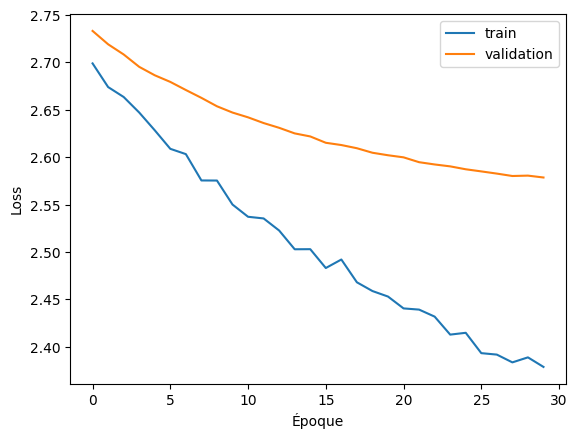

2117902

In [92]:
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

best_ckpt.read(str(CKPT_DIR / "best")).expect_partial()

config = {
    "vocab_size": int(vocab_size),
    "max_length": int(max_length),
    "embedding_dim": EMBEDDING_DIM,
    "rnn_units": RNN_UNITS,
    "start_token_id": int(start_token_id),
    "end_token_id": int(end_token_id),
    "image_size": list(IMAGE_SIZE),
}
(CKPT_DIR / "config.json").write_text(json.dumps(config, indent=2))
(CKPT_DIR / "tokenizer.json").write_text(tokenizer.to_json(), encoding="utf-8")

Captionning

In [93]:
CKPT_DIR = Path("checkpoints")
MAX_WORDS = 20

config = json.loads((CKPT_DIR / "config.json").read_text())
tokenizer = tokenizer_from_json((CKPT_DIR / "tokenizer.json").read_text(encoding="utf-8"))

IMAGE_SIZE = tuple(config["image_size"])
start_token_id = config["start_token_id"]
end_token_id = config["end_token_id"]


inception = InceptionV3(weights="imagenet", include_top=False, pooling=None,
                        input_shape=(*IMAGE_SIZE, 3))
inception.trainable = False
inputs = Input(shape=(*IMAGE_SIZE, 3))
image_encoder = Model(inputs, inception(inputs, training=False))


encoder = CNN_Encoder(config["embedding_dim"])
decoder = RNN_Decoder(config["embedding_dim"], config["rnn_units"], config["vocab_size"])


dummy = encoder(tf.zeros((1, 64, 2048)))
h0, c0 = decoder.reset_state(1)
decoder(tf.constant([[start_token_id]]), dummy, h0, c0)

tf.train.Checkpoint(encoder=encoder, decoder=decoder).read(
    str(CKPT_DIR / "best")
).expect_partial()

BLOCKED_IDS = [0, 1, start_token_id]


def generate_caption(image_path):
    image = tf.io.decode_jpeg(tf.io.read_file(str(image_path)), channels=3)
    image = preprocess_input(tf.image.resize(image, IMAGE_SIZE))
    image = tf.expand_dims(image, axis=0)

    features = tf.reshape(image_encoder(image, training=False), (1, 64, 2048))
    encoded = encoder(features)

    hidden, cell = decoder.reset_state(1)
    word_id = tf.constant([[start_token_id]])

    words = []
    for _ in range(MAX_WORDS):
        logits, hidden, cell, _ = decoder(word_id, encoded, hidden, cell)
        scores = logits[0].numpy()
        scores[BLOCKED_IDS] = -1e9
        predicted_id = int(np.argmax(scores))
        if predicted_id == end_token_id:
            break
        words.append(tokenizer.index_word.get(predicted_id, ""))
        word_id = tf.constant([[predicted_id]])

    return " ".join(words)


def show_caption(image_path):
    caption = generate_caption(image_path)
    plt.imshow(plt.imread(str(image_path)))
    plt.axis("off")
    plt.title(caption, fontsize=10)
    plt.show()
    print("Légende :", caption)

Vérification des resultats

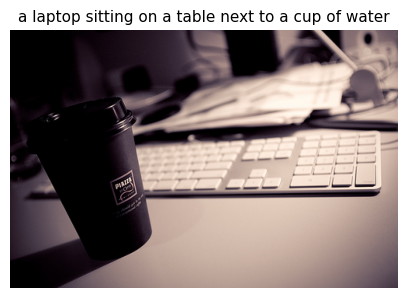

Générée : a laptop sitting on a table next to a cup of water
Références humaines :
  - A cup of coffee sitting next to a computer keyboard.
  - a desk that has a keyboard and a cup on it
  - Black and white photograph of a cup of coffee and a  keyboard.
  - a desk with a cup and a keyboard
  - a coffee cup is next to a white keyboard
------------------------------------------------------------


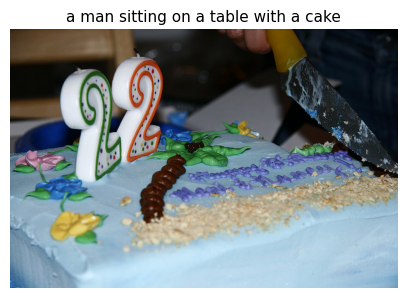

Générée : a man sitting on a table with a cake
Références humaines :
  - a birthday cake is being cut by a knife
  - A birthday cake topped with decorations and the number twenty-two
  - Birthday cake being sliced by a large knife.
  - Someone is cutting the blue birthday cake with two no. 2 candles on it.
  - A sheet cake covered in blue frosting and two number 2 candles.
------------------------------------------------------------


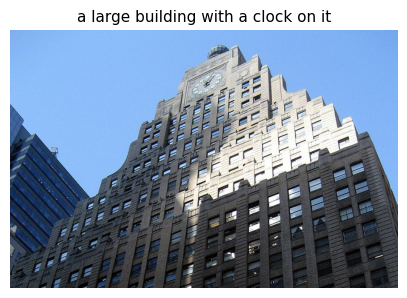

Générée : a large building with a clock on it
Références humaines :
  - A tall building with a lot of windows and a clock.
  - An image of a sky scraper building in the city
  - A large building stands in front of a blue sky.
  - A gray tiered building features hundreds of windows and a clock high up near the top.
  - Looking up at a building with a large face clock near the top.
------------------------------------------------------------


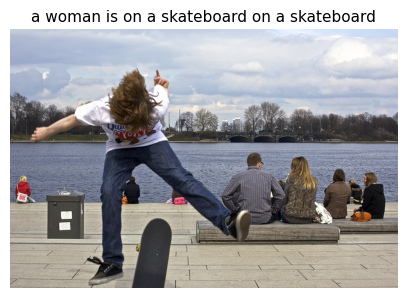

Générée : a woman is on a skateboard on a skateboard
Références humaines :
  - A man does tricks on his skateboard while people look at the scenery.
  - a boy doing a trick with his skate board
  - Boy jumping his skateboard on a riverside walkway.
  - A man that is in the air with a skateboard underneath him.
  - A person doing a trick on a skateboard on a sidewalk.
------------------------------------------------------------


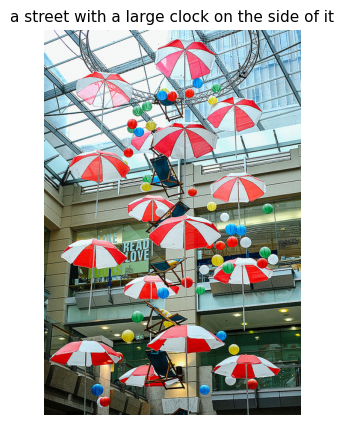

Générée : a street with a large clock on the side of it
Références humaines :
  - A bunch of red and white umbrella hanging from ceiling.
  - An array of umbrellas are hanging on the side of the floors of the mall.
  - A bunch of umbrellas sitting in a building.
  - A bunch of umbrellas and balloons hang from a ceiling.
  - a bunch of umbrellas that are inside of a building
------------------------------------------------------------


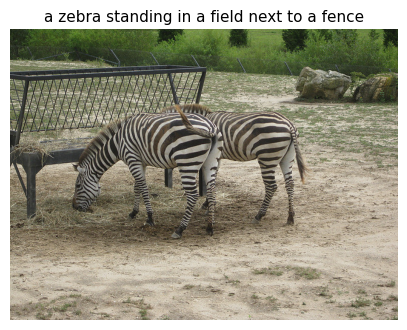

Générée : a zebra standing in a field next to a fence
Références humaines :
  - Two pretty zebras grazing together near a metal structure.
  - two zebra standing next to each other while eating grass
  - Two zebras eating dried grass under a bench.
  - Two zebras eating hay together at a feeder.
  - Two zebras standing in the sand, eating hay.
------------------------------------------------------------


In [94]:
all_val_ids = np.array(sorted(val_records))
rng = np.random.default_rng(1)
sample_ids = rng.choice(all_val_ids, size=6, replace=False)

for image_id in sample_ids:
    record = val_records[int(image_id)]
    generated = generate_caption(record["image_path"])

    plt.figure(figsize=(5, 5))
    plt.imshow(plt.imread(str(record["image_path"])))
    plt.axis("off")
    plt.title(generated, fontsize=11)
    plt.show()

    print("Générée :", generated)
    print("Références humaines :")
    for ref in record["captions"]:
        print("  -", ref.strip())
    print("-" * 60)